# unsupervised learning with galaxy images

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

torch.set_default_dtype(torch.float64)
%matplotlib inline

## get the data
Same as in Lecture 13: 6000 Galaxy10 SDSS galaxies (Leung & Bovy; Galaxy Zoo labels). 
We'll crop the 34×34 images to 32×32 (convenient for halving three times) and keep pixel values in [0, 1].

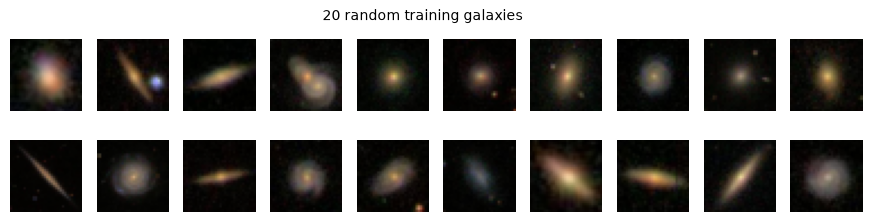

6000 images of 3072 pixels; train 4800, validation 600, test 600


In [2]:
data = np.load('../lec13_cnn/data/galaxy10_subset.npz')
X = torch.tensor(data['images']).permute(0, 3, 1, 2)[:, :, 1:33, 1:33] / 255.
_hidden_labels, class_names = data['labels'].astype(int), list(data['class_names'])
n = len(X)
Xf = X.reshape(n, -1).numpy()                                # n x 3072
perm = np.random.default_rng(17).permutation(n)
i_tr, i_va, i_te = perm[:4800], perm[4800:5400], perm[5400:]
flux = Xf.sum(1) # total brightness of each image

# convenience function for plotting 
show = lambda a, img: (a.imshow(np.clip(img.reshape(3, 32, 32).transpose(1, 2, 0), 0, 1)), a.axis('off'))

fig, ax = plt.subplots(2, 10, figsize=(11, 2.4))
for a, i in zip(ax.ravel(), i_tr[:20]):
    show(a, Xf[i])
plt.suptitle('20 random training galaxies', fontsize=10); plt.show()
print(f'{n} images of {Xf.shape[1]} pixels; train {len(i_tr)}, validation {len(i_va)}, test {len(i_te)}')

## PCA: eigen-galaxies
PCA finds orthogonal directions of largest variance: the eigenvectors of the pixel covariance matrix.
We'll use the `sklearn.decomposition.PCA`:
```
n_comp = 10
pca = PCA(n_comp).fit(Xf[i_tr]) # fit the pca
print(pca.explained_variance_ratio_) # explained variance ratio
print(pca.mean_) # mean galaxy image
print(pca.components_) # eigenvectors
```

1. Fit a PCA with 10 components. Plot the mean galaxy image and the first 8 components. Also plot the explained variance as a function of number of components.

*Hint: use the `show` function above*

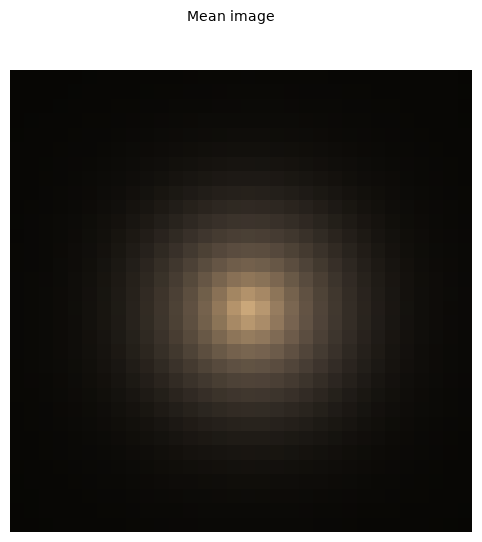

In [20]:
n_comp = 10
pca = PCA(n_comp).fit(Xf[i_tr]) # fit the pca
var_rats = pca.explained_variance_ratio_
meanimg = pca.mean_
eigvecs = pca.components_

mfig, maxis = plt.subplots(1, 1, figsize=(8, 6))
show(maxis,meanimg)
plt.suptitle('Mean image', fontsize=10); plt.show()


#fig, ax = plt.subplots(2, 10, figsize=(11, 2.4))
# for a, i in zip(ax.ravel(), i_tr[:20]):
#    show(a, Xf[i])
# print(f'Variance ratios: {pca.explained_variance_ratio_}') # explained variance ratio
# print(f'Mean galaxy image: {pca.mean_}') # mean galaxy image
# print(f' Eigenvectors: {pca.components_}') # eigenvectors

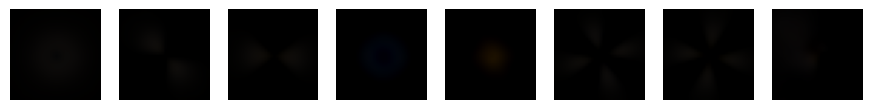

In [22]:

inds = np.linspace(0,7,8).astype(int)
eigfig, eigaxis = plt.subplots(1, 8, figsize=(11, 6))
for a, i in zip(eigaxis, inds):
    show(a, eigvecs[i])

2. Using the snippet below, calculate the MSE of the PCA reconstructions over the test data
```
# get eigenvalues of the test data
eig_val = pca.tansform(Xf[i_te])

# get PCA reconstruction of the test data
Xf_pca = pca.inverse_transform(eig_val)
```
Repeat the exercise using 2, 8, 32 components and report the MSE. 

In [ ]:
# get eigenvalues of the test data
eig_val = pca.tansform(Xf[i_te])

# get PCA reconstruction of the test data
Xf_pca = pca.inverse_transform(eig_val)

compnums = [2,8,32]

## t-SNE
t-SNE places the galaxies in two dimensions so that each galaxy's near neighbors stay near. 
We'll use `sklearn.manifold.TSNE` 

``` 
tsne = TSNE(
    n_components=2,       # Dimension of the embedded space 
    perplexity=30.0,      # Balancing local vs global attention (typical: 5-50)
    init='pca',           # Initialize with PCA to stabilize global geometry
    random_state=0       # Ensures reproducibility across stochastic runs
)
z_tsne = tsne.fit_transform(Xf) # tSNE embedding "z" of the data 
```

Note, TSNE doesn't learn a functional mapping. It optimizes one 2D position per point given so you'll hvae to run `fit_transform` on the entire dataset. Since this is unsupervised learning and we're not doing regression or classification, there are no concerns about overfitting

3. Fit TSNE and plot the 2D embedding as a scatter plot. Pick a random galaxy, find its 5 nearest neighbors in the embedding space based on Euclidean geometry. Plot the images of galaxy and its five neighbors.

## Autoencoders
An autoencoder is two networks trained together: an **encoder** $z = g_\phi(x)$ that compresses an image to a short latent vector $z$ (here $k$ numbers), and a **decoder** $\hat x = f_\theta(z)$ that rebuilds the image from it. 

The training target is the input itself:

$$\mathcal L(\phi,\theta) = \frac1N\sum_i \lVert x_i - f_\theta(g_\phi(x_i))\rVert^2 ,$$

the Gaussian negative log-likelihood. 
The bottleneck ($k \ll 3072$) forces the network to keep only what matters most for reconstruction. 

4. I've given you below a convolutional autoencoder (CAE). Train a CAE with `k=8` latent components using the Gaussian negative log-likelihood (aka MSE) loss (`F.mse_loss`). Use minibatches, Adam optimier, early stopping... you know the drill

In [ ]:
class ConvAE(nn.Module):
    ''' The encoder should be familiar: conv -> ReLU -> pool -> linear layer down to k numbers. 
    The decoder mirrors it: a linear layer back up to 64 maps of 4×4, then upsample -> conv -> ReLU three times back to 3×32×32.
    '''
    def __init__(self, k):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # 16 x 16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 8 x 8
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 4 x 4
            nn.Flatten(), nn.Linear(64 * 16, k))                              # latent z
        self.dec = nn.Sequential(
            nn.Linear(k, 64 * 16), nn.ReLU(), nn.Unflatten(1, (64, 4, 4)),
            nn.Upsample(scale_factor=2), nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(),   # 8 x 8
            nn.Upsample(scale_factor=2), nn.Conv2d(32, 16, 3, padding=1), nn.ReLU(),   # 16 x 16
            nn.Upsample(scale_factor=2), nn.Conv2d(16, 3, 3, padding=1))              # 32 x 32

    def forward(self, x):
        # forward pass, runs the encoder *and* decoder
        return self.dec(self.enc(x))

In [ ]:
def train_ae(model, epochs=60, patience=8, lr=1e-3, seed=1):
    torch.manual_seed(seed)
    # training loop

    
    model.load_state_dict(best_state)
    return model.eval(), curve

5. Calculate the MSE on the test data for the CAE reconstructions. Compare it to the MSE of the PCA with the same number of componenets. Pick 5 galaxies at random, plot 3 rows: (1) original galaxy image, (2) PCA reconstruciton and (3) convolutional autoencoder reconstruction. 

**Optional**

6. Train a CAE with just two components. Run just the encoder on the data to get the latent CAE embedding "z_cae" of the data. Plot the 2D latent space. Then similar to the TSNE exercise, pick a random galaxy and 5 nearest neighbors in the latent space and compare their images. 

7. Walk through latent space: Pick two points in the latent space such that a line that crosses through them goes through the overall data. Sample z_cae along that line, plug it into the decoder and plot the image generated. 